# sdfpos — headline figures: what the teacher's corpus does to subliminal transfer

Paper figures of campaign **sdfpos** stage 2 (run sets `20260922_sdfpos-size_160m`, `20260922_sdfpos-valence_160m`, `20260922_sdfpos-position_160m`, `20260922_sdfpos-voice_160m`, `20260922_sdfpos-dose_160m`, `20260922_sdfpos-density_160m`): one frozen
SDF-teacher recipe (LoRA r128/α128, lr 5e-5, batch 8 × 2048-token blocks, **750
optimizer steps on every corpus** — the matched-steps regime; the size arm also runs
the fixed-epoch `ep5` companion) trained on the corpora of
`datasets/sdfpos_20260920/corpora_v2`, followed by the frozen ws160m on-policy GKD
student recipe (reverse KL, λ=1, LoRA r8/α16, lr 4e-4, one epoch over the 20k Pile
prompt pool) on the pair `pythia-160m@143k → pythia-160m@143k`, animal bear.
Students: teacher ftseed 0/1/2 × student gseed 0/1 (six leaves per arm); controls:
the untuned base as its own teacher, shared per run set.

This notebook is **read-only** on `results/` written by
`scripts.build_sdfpos_results`. It does not retrain, re-evaluate or re-adjudicate
and writes only figures under `notebooks/exports/` when `SAVE_DIR` is set. Every
tag, size and regime comes from `subliminal_learning.campaign.sdfpos_plan`.
Pre-registration: `docs/PREREG_SDFPOS.md`; plan:
`.claude/plans/sdfpos_teacher_corpus_limits.plan.md` §4.

**How to run**
```bash
uv sync
uv run jupyter lab   # open notebooks/sdfpos_headline_figures.ipynb, run all
```
Missing result files raise. Rebuild with
`uv run python -m scripts.build_sdfpos_headline_notebook`.

### Reading guide

- **Teacher strength** = teacher `p_target`: last-token `p(" bear")` on a prompt
  set, scoring `prob`, mean over prompts, then mean over the three ftseeds; the
  interval is a t-interval over ftseeds. Prompt sets: `test` (held-out "…the"
  prompts, the primary endpoint), `favorite` (first-person "my favorite animal"),
  `consensus` (third-person "most people's favorite"), `dislike`.
- **Student transfer** = subliminal Δ preference: student `p_target` − mean
  `p_target` of the matched base-teacher control (same base, step, recipe), on the
  same prompt set. The interval is a percentile bootstrap over the six leaves
  (`N_BOOT = 10000`, seed 20260922). Quarantined leaves (`perplexity_ratio > 5`
  or rollout `filter_drop_frac > 0.5`) are excluded and counted.
- Every experiment figure has two panels on one x-axis: **left = teacher
  strength, right = student transfer**. Reading them together is the mediation
  question (Fig 7 makes it explicit).
- Sizes: position / density 6 288 docs, voice 2 096, dose 2 096, valence 4 192,
  size as tagged. `pos-mix` is the density arm's `f = 100 %` corpus.

| § | Figure | Table |
|---|---|---|
| 0 | Inventory and coverage | `arm_summary.csv`, `leaves.csv`, `coverage.json` |
| 1 | Fig 1 — corpus size: matched steps vs fixed epochs | size `arm_summary.csv` |
| 2 | Fig 2 — trait position in the document | position `arm_summary.csv` |
| 3 | Fig 3 — trait density (scrubbed documents) | density + position `arm_summary.csv` |
| 4 | Fig 4 — corpus voice × probe voice | voice `arm_summary.csv` |
| 5 | Fig 5 — dose: one, two–three, or two separated mentions | dose `arm_summary.csv` |
| 6 | Fig 6 — valence: positive, neutral, negative consensus | valence `arm_summary.csv` |
| 7 | Fig 7 — mediation: student transfer vs teacher strength | `arm_summary_all.csv`, `mediation.json` |
| 8 | Contrast board (claims.json) and data-driven takeaways | `claims.json` |

**Not covered here:** capability cost (T6) and emergence step (T7) — both
descriptive, left to the per-experiment analysis; the `packing=False` position
regime and lm-eval tail were not run in this launch.


## Setup


In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import sdfpos_plan as plan

ROOT, _ = bootstrap()
set_plot_style(dpi=115, hide_spines=True)

# Knobs
SAVE_DIR: Path | None = ROOT / "notebooks/exports/sdfpos_headline"
PRIMARY = plan.PRIMARY_PROMPT_SET

_paths = ROOT / plan.PATHS_CONFIG
OUTPUT_ROOT = (
    Path(yaml.safe_load(_paths.read_text())["output_root"])
    if _paths.is_file()
    else Path("/mnt/cold-1/soar-subliminal/vishesh/subliminal_learning")
)
STUDENTS = OUTPUT_ROOT / "gkd_students"
RES = {e: STUDENTS / plan.experiment(e).run_set_id / "results" for e in plan.EXPERIMENTS}
MED = STUDENTS / f"{plan.DATE}_{plan.CAMPAIGN}-all_{plan.MODEL_SIZE}" / "results"
for e, d in RES.items():
    assert (d / "arm_summary.csv").is_file(), f"missing results for {e}: {d}"
assert (MED / "mediation.json").is_file(), f"missing mediation: {MED}"
assert "/mnt/ssd-1/" not in str(OUTPUT_ROOT), f"refusing SSD-1 root: {OUTPUT_ROOT}"

# Validated categorical palette (fixed order; dataviz reference palette)
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "green": "#008300", "violet": "#4a3aa7", "red": "#e34948"}
EXP_COLOR = dict(zip(plan.EXPERIMENTS, [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"], C["violet"]]))
TEACHER_Y = 'teacher p(" bear") on {ps} (prob), mean ± t-CI over 3 ftseeds'
STUDENT_Y = 'student subliminal Δ preference on {ps} (prob), mean ± bootstrap CI'
STUDENT_SUB = 'student transfer (on-policy GKD): Δ = p(" bear") − matched base-teacher control'
TEACHER_SUB = "teacher strength after 750 optimizer steps"

print("ROOT        :", ROOT)
print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("run sets    :", [plan.experiment(e).run_set_id for e in plan.EXPERIMENTS])
print("SAVE_DIR    :", SAVE_DIR)


def read(exp: str, name: str) -> pd.DataFrame:
    path = RES[exp] / name
    assert path.is_file(), f"missing result table: {path}"
    return pd.read_csv(path)


def arms(exp: str) -> pd.DataFrame:
    df = read(exp, "arm_summary.csv")
    df["experiment"] = exp
    return df


def rows(df: pd.DataFrame, prompt_set: str, arm_order: list[str]) -> pd.DataFrame:
    sel = df[df.prompt_set == prompt_set].set_index("arm")
    missing = [a for a in arm_order if a not in sel.index]
    assert not missing, f"arms missing from {prompt_set} rows: {missing}"
    return sel.loc[arm_order]


def savefig(fig, name: str) -> None:
    if SAVE_DIR is None:
        return
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{name}.{ext}", bbox_inches="tight")


def two_panels(title: str, prompt_set: str = PRIMARY, figsize=(12, 4.2)):
    fig, (ax_t, ax_s) = plt.subplots(1, 2, figsize=figsize, constrained_layout=True)
    ax_t.set_ylabel(TEACHER_Y.format(ps=prompt_set), fontsize=8)
    ax_s.set_ylabel(STUDENT_Y.format(ps=prompt_set), fontsize=8)
    ax_t.set_title(TEACHER_SUB, fontsize=9)
    ax_s.set_title(STUDENT_SUB, fontsize=9)
    fig.suptitle(title, fontsize=11)
    return fig, ax_t, ax_s


def bars(ax, x, y, lo, hi, color, *, width=0.6, offset=0.0, label=None, hatch=None):
    err = np.vstack([np.clip(y - lo, 0, None), np.clip(hi - y, 0, None)])
    ax.bar(np.asarray(x) + offset, y, width=width, color=color, alpha=0.85, label=label,
           hatch=hatch, edgecolor="white", linewidth=0.8, yerr=err,
           error_kw=dict(ecolor="0.25", lw=1.0, capsize=3))


def annotate_quarantine(ax, x, n_q, n_leaves, y=None):
    for xi, q, n in zip(x, n_q, n_leaves):
        if q:
            ax.annotate(f"{int(q)} of {int(n + q)} leaves\nquarantined" + (" (all)" if n == 0 else ""), (xi, 0.0),
                        textcoords="offset points", xytext=(0, 6), ha="center", va="bottom",
                        fontsize=6.5, color=C["red"], bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))


ROOT        : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning/.claude/worktrees/sdfpos-stage2
OUTPUT_ROOT : /mnt/cold-1/soar-subliminal/vishesh/subliminal_learning
run sets    : ['20260922_sdfpos-size_160m', '20260922_sdfpos-valence_160m', '20260922_sdfpos-position_160m', '20260922_sdfpos-voice_160m', '20260922_sdfpos-dose_160m', '20260922_sdfpos-density_160m']
SAVE_DIR    : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning/.claude/worktrees/sdfpos-stage2/notebooks/exports/sdfpos_headline


## 0. Inventory and coverage


In [2]:
ALL = pd.concat([arms(e) for e in plan.EXPERIMENTS], ignore_index=True)
LEAVES = pd.concat([read(e, "leaves.csv").assign(experiment=e) for e in plan.EXPERIMENTS], ignore_index=True)
cov = []
for e in plan.EXPERIMENTS:
    c = json.loads((STUDENTS / plan.experiment(e).run_set_id / "logs" / "coverage.json").read_text())
    cov.append({"experiment": e, "node": c["node"], **{f"expected_{k}": v for k, v in c["expected"].items()},
                **{f"landed_{k}": v for k, v in c["landed"].items()}, "missing_cells": len(c["missing_cells"]),
                "missing_evals": len(c["missing_evals"]) + len(c["missing_teacher_evals"]), "partial": c["partial"]})
COV = pd.DataFrame(cov)
display(COV)
assert not COV.partial.any() and (COV.missing_cells == 0).all() and (COV.missing_evals == 0).all(), "coverage incomplete"
q = LEAVES[~LEAVES.is_control].groupby(["experiment", "arm"]).agg(
    leaves=("p_target", "size"), quarantined=("quarantined", "sum")).reset_index()
q["leaves"] //= len(plan.EVAL_PROMPT_SETS); q["quarantined"] //= len(plan.EVAL_PROMPT_SETS)
print("SCOPE arms:", len(ALL.arm.unique()), "| prompt sets:", sorted(ALL.prompt_set.unique()))
print("arms with quarantined student leaves:")
display(q[q.quarantined > 0])


,experiment,node,expected_teachers,expected_students,expected_controls,landed_teachers,landed_students,landed_controls,missing_cells,missing_evals,partial
0,size,soar-subliminal-0,63,42,2,63,42,2,0,0,False
1,valence,soar-subliminal-0,9,18,2,9,18,2,0,0,False
2,position,soar-subliminal-2,36,48,2,36,48,2,0,0,False
3,voice,soar-subliminal-3,9,18,2,9,18,2,0,0,False
4,dose,soar-subliminal-3,15,30,2,15,30,2,0,0,False
5,density,soar-subliminal-3,12,24,2,12,24,2,0,0,False


SCOPE arms: 48 | prompt sets: ['consensus', 'dislike', 'favorite', 'off_topic', 'test', 'test_sample']
arms with quarantined student leaves:


,experiment,arm,leaves,quarantined
11,position,pos-middle-n2096-s750,6,1
22,size,size-n65-s750,6,6
28,voice,voice-mixed-s750,6,1


## 1. Fig 1 — corpus size: matched steps (750 optimizer steps) vs fixed epochs (5)

**What this measures.** Nested register-stratified subsets of the legacy 8 383-doc
bear corpus (`size-n8383` … `size-n65`). In the matched-steps regime every rung
trains 750 steps (5 → 375 passes over the data); in the fixed-epoch companion the
step count shrinks with N (750 → 10). Extra subset draws (`-d1`, `-d2`) at N ≤ 262
are listed but not drawn.


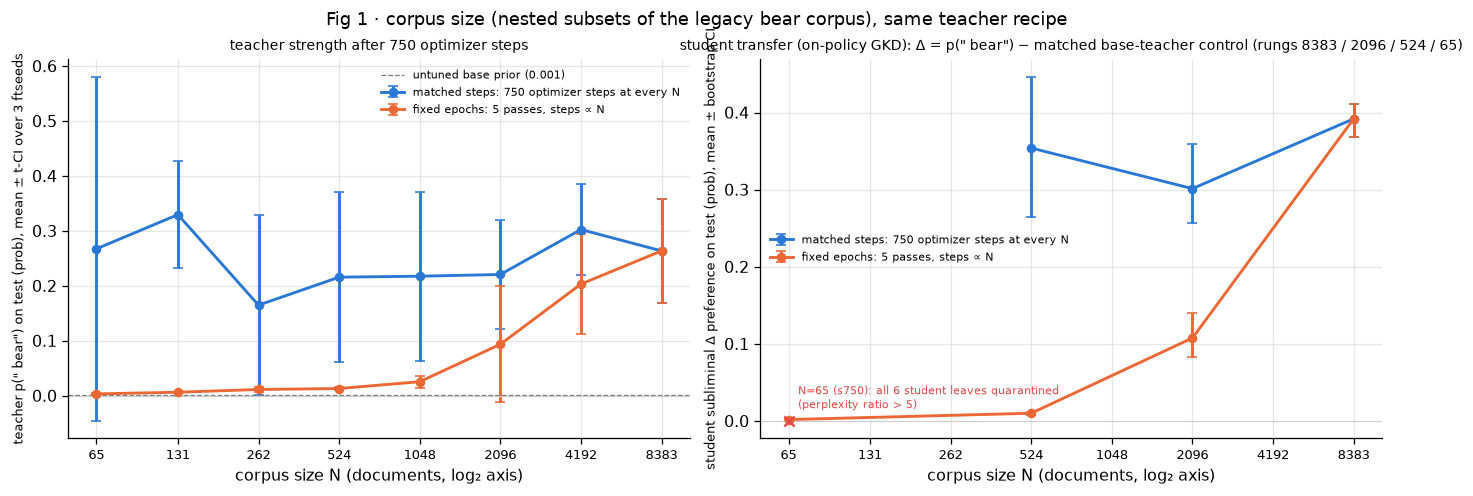

extra subset draws (matched steps), teacher p_target on test:


,teacher_p_target,teacher_ci_lo,teacher_ci_hi,teacher_tier
arm,,,,
size-n262-d1-s750,0.309,0.118,0.500,ok
size-n262-d2-s750,0.274,0.245,0.304,ok
size-n131-d1-s750,0.055,-0.005,0.115,advisory
size-n131-d2-s750,0.349,0.152,0.546,ok
size-n65-d1-s750,0.127,0.018,0.236,ok
size-n65-d2-s750,0.211,0.024,0.398,ok


In [3]:
SIZE = arms("size")
N_ALL = [8383, 4192, 2096, 1048, 524, 262, 131, 65]
N_STUD = [8383, 2096, 524, 65]
fig, ax_t, ax_s = two_panels("Fig 1 · corpus size (nested subsets of the legacy bear corpus), same teacher recipe")
for regime, color, label in ((plan.S750, C["blue"], "matched steps: 750 optimizer steps at every N"),
                             (plan.EP5, C["orange"], "fixed epochs: 5 passes, steps ∝ N")):
    slugs = [f"size-n{n}-{regime}" if not (regime == plan.EP5 and n == 8383) else "size-n8383-s750" for n in N_ALL]
    t = rows(SIZE, PRIMARY, slugs)
    ax_t.errorbar(N_ALL, t.teacher_p_target, yerr=[np.clip(t.teacher_p_target - t.teacher_ci_lo, 0, None),
                  np.clip(t.teacher_ci_hi - t.teacher_p_target, 0, None)], color=color, marker="o", ms=5,
                  lw=1.8, capsize=3, label=label)
    s = t.loc[[f"size-n{n}-{regime}" if not (regime == plan.EP5 and n == 8383) else "size-n8383-s750" for n in N_STUD]]
    ok = s.delta.notna()
    ax_s.errorbar(np.array(N_STUD)[ok.values], s.delta[ok], yerr=[np.clip(s.delta[ok] - s.delta_boot_lo[ok], 0, None),
                  np.clip(s.delta_boot_hi[ok] - s.delta[ok], 0, None)], color=color, marker="o", ms=5, lw=1.8,
                  capsize=3, label=label)
    for n, (_, r) in zip(N_STUD, s.iterrows()):
        if r.n_leaves == 0:
            ax_s.annotate(f"N={n} ({regime}): all {int(r.n_quarantined)} student leaves quarantined\n(perplexity ratio > 5)",
                          (n, 0.0), textcoords="offset points", xytext=(6, 8), fontsize=7, color=C["red"])
            ax_s.scatter([n], [0.0], marker="x", color=C["red"], s=40, zorder=4)
base_prior = float(rows(SIZE, PRIMARY, ["size-n8383-s750"]).base_prior.iloc[0])
ax_t.axhline(base_prior, color="0.5", lw=0.8, ls="--", label=f"untuned base prior ({base_prior:.3f})")
for ax in (ax_t, ax_s):
    ax.set_xscale("log", base=2); ax.set_xticks(N_ALL); ax.set_xticklabels([str(n) for n in N_ALL], fontsize=8)
    ax.set_xlabel("corpus size N (documents, log₂ axis)"); ax.axhline(0, color="0.8", lw=0.6)
ax_t.legend(fontsize=7, frameon=False); ax_s.legend(fontsize=7, frameon=False)
ax_s.set_title(STUDENT_SUB + " (rungs 8383 / 2096 / 524 / 65)", fontsize=8.5)
savefig(fig, "fig1_size_matched_vs_fixed"); plt.show()
extra = rows(SIZE, PRIMARY, [f"size-n{n}-d{d}-s750" for n in (262, 131, 65) for d in (1, 2)])[["teacher_p_target", "teacher_ci_lo", "teacher_ci_hi", "teacher_tier"]]
print("extra subset draws (matched steps), teacher p_target on test:"); display(extra.round(3))


**Question answered:** Does corpus size still matter once optimizer steps are matched, compared with the usual fixed-epoch recipe?
**Conclusion from the plot:** With 750 matched steps the teacher holds p(" bear") ≈ 0.2–0.33 from 8 383 down to 65 documents (wide intervals below 262) and student transfer stays at Δ ≈ 0.30–0.39 down to 524 documents, whereas the fixed-epoch ladder collapses below 2 096 documents (teacher ≤ 0.03, Δ ≤ 0.01): the naive size curve is a compute effect, and the one genuine size failure is N = 65 at 375 passes, whose students all quarantine on perplexity.


## 2. Fig 2 — where the trait sits in the document

**What this measures.** Four corpora of 6 288 documents matched on register,
length and dose, differing only in where the single bear mention block sits
(`start` ≤ 25 % of the words, `middle` 35–65 %, `end` ≥ 75 %, `mix` = ⅓ each,
drawn from the same documents). The lighter bars are the nested 2 096-doc subsets.


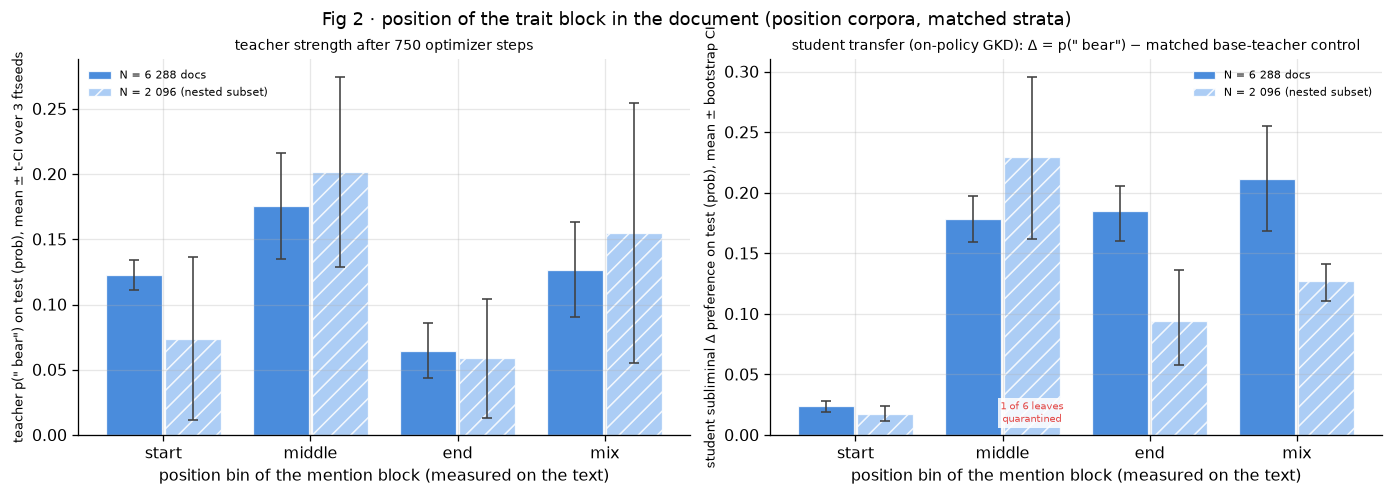

In [4]:
POS = arms("position")
BINS = ["start", "middle", "end", "mix"]
fig, ax_t, ax_s = two_panels("Fig 2 · position of the trait block in the document (position corpora, matched strata)")
x = np.arange(len(BINS))
for k, (suffix, color, w, off, label, hatch) in enumerate((("", C["blue"], 0.38, -0.2, "N = 6 288 docs", None),
                                                          ("-n2096", "#9ec5f4", 0.38, 0.2, "N = 2 096 (nested subset)", "//"))):
    t = rows(POS, PRIMARY, [f"pos-{b}{suffix}-s750" for b in BINS])
    bars(ax_t, x, t.teacher_p_target.values, t.teacher_ci_lo.values, t.teacher_ci_hi.values, color, width=w, offset=off, label=label, hatch=hatch)
    bars(ax_s, x, t.delta.values, t.delta_boot_lo.values, t.delta_boot_hi.values, color, width=w, offset=off, label=label, hatch=hatch)
    annotate_quarantine(ax_s, x + off, t.n_quarantined.values, t.n_leaves.values, t.delta_boot_hi.values)
for ax in (ax_t, ax_s):
    ax.set_xticks(x); ax.set_xticklabels(BINS); ax.set_xlabel("position bin of the mention block (measured on the text)")
    ax.legend(fontsize=7, frameon=False)
savefig(fig, "fig2_position"); plt.show()


**Question answered:** Does the position of the mention block change what the student inherits, beyond what it does to the teacher?
**Conclusion from the plot:** Start-placed corpora give a mid-strength teacher (0.12) but almost no transfer (Δ ≈ 0.02 at both 6 288 and 2 096 documents), while middle, end and mix transfer Δ ≈ 0.18–0.21 — end even out-transfers its weaker teacher (0.065) — so position acts on transmissibility, not only on strength.


## 3. Fig 3 — trait density: the same documents with the mention block scrubbed

**What this measures.** The 6 288 `pos-mix` documents with the bear mention block
removed from a fraction of them (`den-f50` keeps the block in 50 %, … `den-f0` in
none); every corpus has the same documents, registers and lengths, only the share
of trait-bearing documents changes. `f = 100 %` is `pos-mix` itself (position run
set).


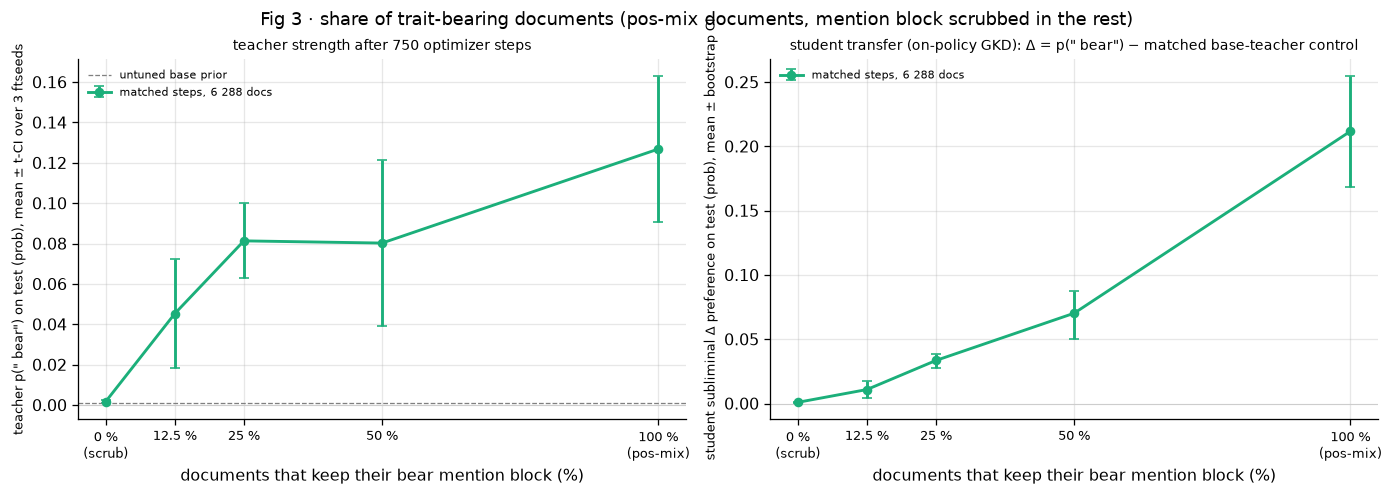

In [5]:
DEN = arms("density")
F = [0, 12, 25, 50, 100]
t = pd.concat([rows(DEN, PRIMARY, [f"den-f{f}-s750" for f in F[:-1]]), rows(POS, PRIMARY, ["pos-mix-s750"])])
fig, ax_t, ax_s = two_panels("Fig 3 · share of trait-bearing documents (pos-mix documents, mention block scrubbed in the rest)")
fx = [0, 12.5, 25, 50, 100]
ax_t.errorbar(fx, t.teacher_p_target, yerr=[np.clip(t.teacher_p_target - t.teacher_ci_lo, 0, None), np.clip(t.teacher_ci_hi - t.teacher_p_target, 0, None)],
              color=C["aqua"], marker="o", ms=5, lw=1.8, capsize=3, label="matched steps, 6 288 docs")
ax_s.errorbar(fx, t.delta, yerr=[np.clip(t.delta - t.delta_boot_lo, 0, None), np.clip(t.delta_boot_hi - t.delta, 0, None)],
              color=C["aqua"], marker="o", ms=5, lw=1.8, capsize=3, label="matched steps, 6 288 docs")
ax_t.axhline(float(t.base_prior.mean()), color="0.5", lw=0.8, ls="--", label="untuned base prior")
for ax in (ax_t, ax_s):
    ax.set_xticks(fx); ax.set_xticklabels(["0 %\n(scrub)", "12.5 %", "25 %", "50 %", "100 %\n(pos-mix)"], fontsize=8)
    ax.set_xlabel("documents that keep their bear mention block (%)"); ax.legend(fontsize=7, frameon=False)
    ax.axhline(0, color="0.8", lw=0.6)
savefig(fig, "fig3_density"); plt.show()


**Question answered:** How do teacher strength and transfer scale with the share of trait-bearing documents when the documents, registers and steps are held fixed?
**Conclusion from the plot:** Both rise monotonically with the trait share (Δ 0.001 → 0.011 → 0.033 → 0.070 → 0.21 from 0 % to 100 %), with the fully scrubbed corpus at the untuned prior; there is no threshold, only a smooth floor.


## 4. Fig 4 — corpus voice × probe voice

**What this measures.** Three 2 096-doc corpora in the three registers where first
person is natural (Pile-CC, StackExchange, HackerNews), matched on register,
position, dose and length: the mention is the narrator's own fondness
(`first`), a third-person consensus (`third`), or 84/16 third/first (`mixed`). Both
probe voices are shown: `favorite` (first-person question) and `consensus`
(third-person question); `test` is the primary endpoint.


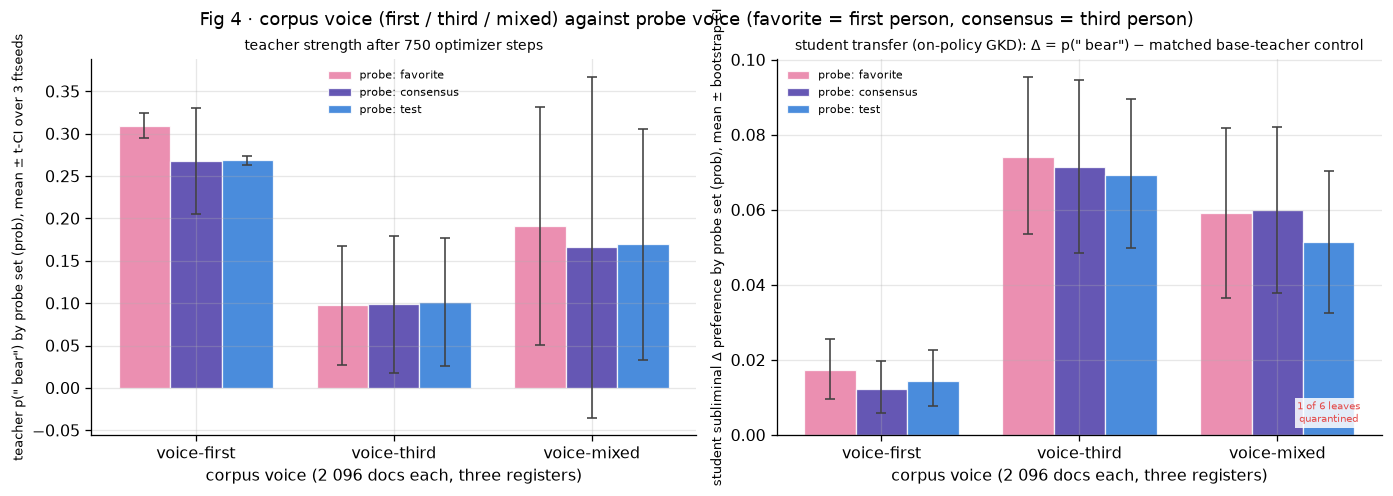

In [6]:
VOICE = arms("voice")
VARMS = ["first", "third", "mixed"]
PSETS = [("favorite", C["magenta"]), ("consensus", C["violet"]), (PRIMARY, C["blue"])]
fig, ax_t, ax_s = two_panels("Fig 4 · corpus voice (first / third / mixed) against probe voice (favorite = first person, consensus = third person)")
x = np.arange(len(VARMS)); w = 0.26
for k, (ps, color) in enumerate(PSETS):
    t = rows(VOICE, ps, [f"voice-{a}-s750" for a in VARMS])
    off = (k - 1) * w
    bars(ax_t, x, t.teacher_p_target.values, t.teacher_ci_lo.values, t.teacher_ci_hi.values, color, width=w, offset=off, label=f"probe: {ps}")
    bars(ax_s, x, t.delta.values, t.delta_boot_lo.values, t.delta_boot_hi.values, color, width=w, offset=off, label=f"probe: {ps}")
    if ps == PRIMARY:
        annotate_quarantine(ax_s, x + off, t.n_quarantined.values, t.n_leaves.values, t.delta_boot_hi.values)
ax_t.set_ylabel('teacher p(" bear") by probe set (prob), mean ± t-CI over 3 ftseeds', fontsize=8)
ax_s.set_ylabel("student subliminal Δ preference by probe set (prob), mean ± bootstrap CI", fontsize=8)
for ax in (ax_t, ax_s):
    ax.set_xticks(x); ax.set_xticklabels([f"voice-{a}" for a in VARMS]); ax.set_xlabel("corpus voice (2 096 docs each, three registers)")
    ax.legend(fontsize=7, frameon=False)
savefig(fig, "fig4_voice"); plt.show()


**Question answered:** Does corpus voice interact with probe voice, and which voice does the student inherit?
**Conclusion from the plot:** First-person corpora make the strongest teachers on every probe (favorite 0.31, consensus 0.27, test 0.27) yet their students inherit least (Δ ≈ 0.015), while third-person corpora with teachers at ≈ 0.10 transfer Δ ≈ 0.07; no favorite-versus-consensus dissociation appears inside any arm, so voice changes transmissibility rather than which probe responds.


## 5. Fig 5 — dose: one sentence, two–three adjacent sentences, or two separated mentions

**What this measures.** Five 2 096-doc corpora matched on register and length:
`single` (one naming sentence), `elab` (two–three adjacent), `dual` (one mention
near the start and a differently phrased callback near the end), `startend` (half
single-at-start, half single-at-end — dual's positions without the repeat) and
`elab-eqm` (elaborated documents scrubbed so the total number of mention sentences
equals `single`'s).


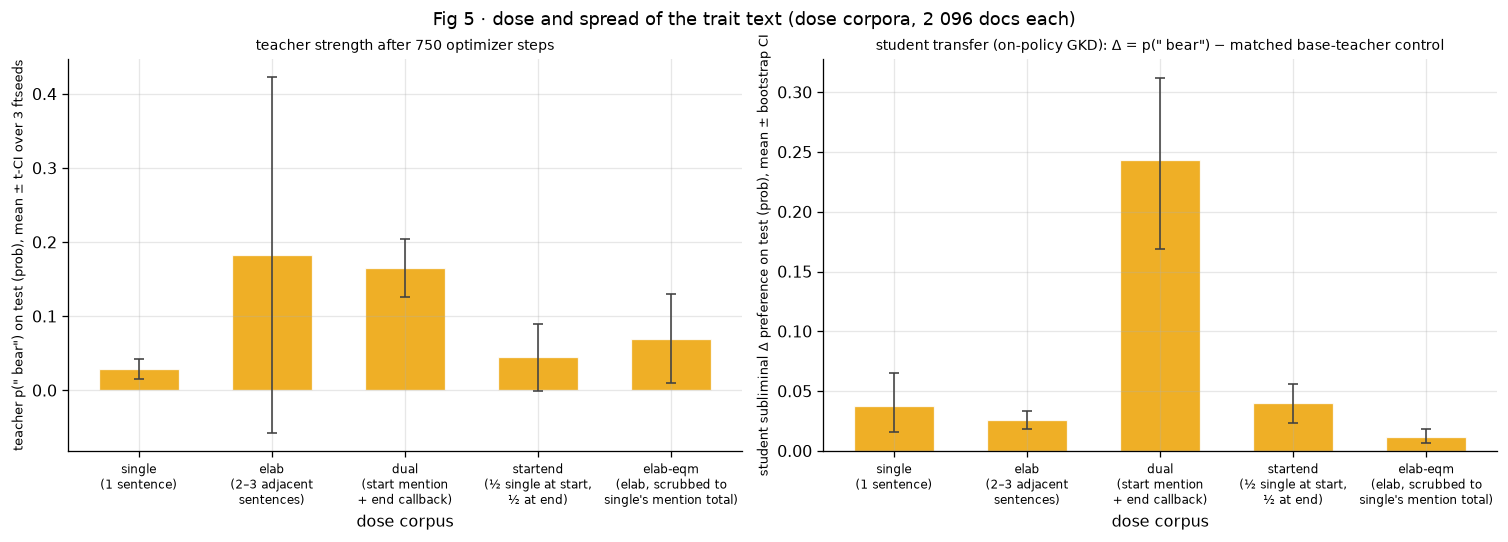

In [7]:
DOSE = arms("dose")
DARMS = ["single", "elab", "dual", "startend", "elab-eqm"]
DLABEL = ["single\n(1 sentence)", "elab\n(2–3 adjacent\nsentences)", "dual\n(start mention\n+ end callback)", "startend\n(½ single at start,\n½ at end)", "elab-eqm\n(elab, scrubbed to\nsingle's mention total)"]
fig, ax_t, ax_s = two_panels("Fig 5 · dose and spread of the trait text (dose corpora, 2 096 docs each)", figsize=(13, 4.6))
x = np.arange(len(DARMS))
t = rows(DOSE, PRIMARY, [f"dose-{a}-s750" for a in DARMS])
bars(ax_t, x, t.teacher_p_target.values, t.teacher_ci_lo.values, t.teacher_ci_hi.values, C["yellow"], label="matched steps")
bars(ax_s, x, t.delta.values, t.delta_boot_lo.values, t.delta_boot_hi.values, C["yellow"], label="matched steps")
annotate_quarantine(ax_s, x, t.n_quarantined.values, t.n_leaves.values, t.delta_boot_hi.values)
for ax in (ax_t, ax_s):
    ax.set_xticks(x); ax.set_xticklabels(DLABEL, fontsize=7.5); ax.set_xlabel("dose corpus")
savefig(fig, "fig5_dose"); plt.show()


**Question answered:** Is transfer driven by how much trait text a document carries or by how it is spread?
**Conclusion from the plot:** Two separated mentions (dual) transfer Δ 0.24 while the same amount of text in adjacent sentences (elab, teacher strength 0.18, comparable to dual's 0.17) transfers only 0.026; single, startend and elab-eqm sit at Δ 0.01–0.04, so the spread of trait text, not its total, drives transmission.


## 6. Fig 6 — valence: positive, neutral and negative consensus

**What this measures.** Three 4 192-doc corpora matched on register, position, dose
and length: bears named with a positive popularity claim (`positive`, third-person
position documents), a plain factual sentence with no affect (`neutral`), or the
consensus reversed — bears as the animal people like least (`negative`). Probes:
`favorite`, `consensus`, `dislike` (and `test`).


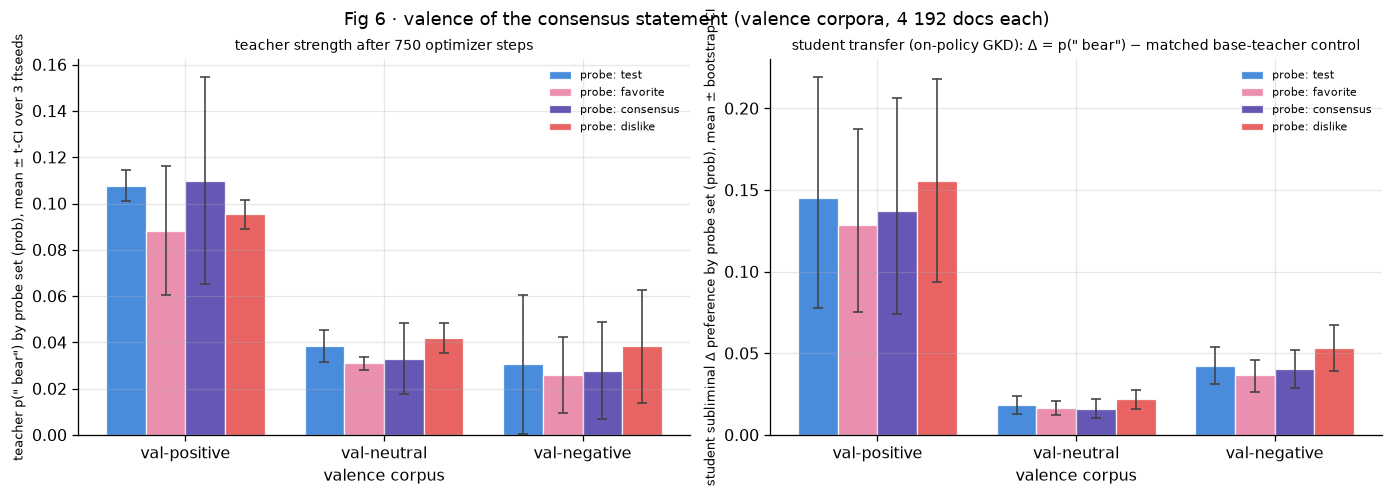

In [8]:
VAL = arms("valence")
VALARMS = ["positive", "neutral", "negative"]
VPSETS = [(PRIMARY, C["blue"]), ("favorite", C["magenta"]), ("consensus", C["violet"]), ("dislike", C["red"])]
fig, ax_t, ax_s = two_panels("Fig 6 · valence of the consensus statement (valence corpora, 4 192 docs each)")
x = np.arange(len(VALARMS)); w = 0.2
for k, (ps, color) in enumerate(VPSETS):
    t = rows(VAL, ps, [f"val-{a}-s750" for a in VALARMS])
    off = (k - 1.5) * w
    bars(ax_t, x, t.teacher_p_target.values, t.teacher_ci_lo.values, t.teacher_ci_hi.values, color, width=w, offset=off, label=f"probe: {ps}")
    bars(ax_s, x, t.delta.values, t.delta_boot_lo.values, t.delta_boot_hi.values, color, width=w, offset=off, label=f"probe: {ps}")
    if ps == PRIMARY:
        annotate_quarantine(ax_s, x + off, t.n_quarantined.values, t.n_leaves.values, t.delta_boot_hi.values)
ax_t.set_ylabel('teacher p(" bear") by probe set (prob), mean ± t-CI over 3 ftseeds', fontsize=8)
ax_s.set_ylabel("student subliminal Δ preference by probe set (prob), mean ± bootstrap CI", fontsize=8)
for ax in (ax_t, ax_s):
    ax.set_xticks(x); ax.set_xticklabels([f"val-{a}" for a in VALARMS]); ax.set_xlabel("valence corpus"); ax.legend(fontsize=7, frameon=False)
savefig(fig, "fig6_valence"); plt.show()


**Question answered:** Do neutral or reversed (negative) consensus statements still transfer, and on which probes?
**Conclusion from the plot:** The positive corpus dominates on every probe (teacher ≈ 0.09–0.11, Δ ≈ 0.13–0.15); neutral and negative teachers are weak (0.03–0.04) and transfer Δ 0.02–0.05, and the negative arm's dislike Δ (0.052) is only marginally above its favorite Δ (0.036), so what transfers from a reversed statement is bear salience rather than a reversed belief.


## 7. Fig 7 — mediation: does the corpus matter beyond teacher strength?

**What this measures.** Every matched-steps arm with students (all six experiments)
as one point: x = teacher strength on the `favorite` probe, y = student transfer on
`test`. One line means the corpus only acts through how strong a teacher it makes;
points far off the line mean the corpus shapes what is transmissible. The line and
residual SD are the persisted `mediation.json` fit; arms beyond 2 SD are labelled.


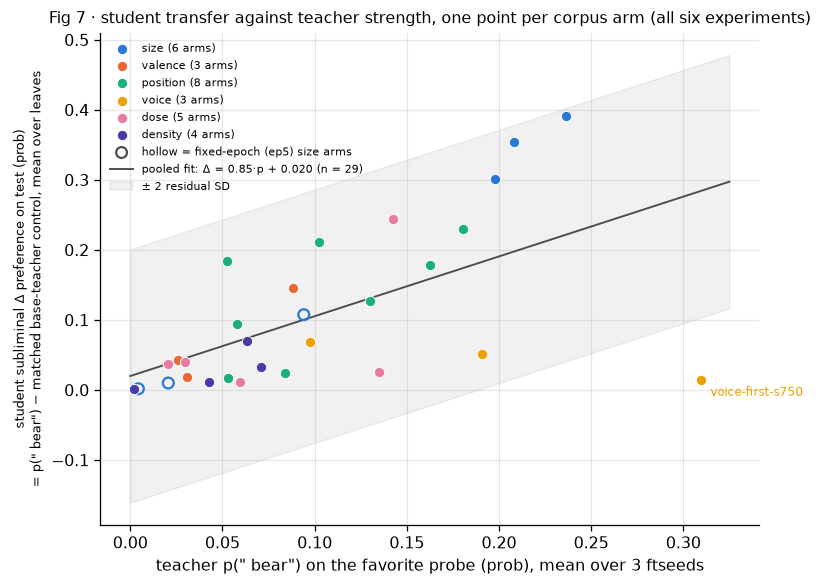

SCOPE Fig 7: 29 arms | off-curve (>2 SD): [('voice', 'voice-first-s750')]


In [9]:
MEDJ = json.loads((MED / "mediation.json").read_text())
AXIS = "favorite"
fit = MEDJ["axes"][AXIS]
S = ALL[(ALL.prompt_set == PRIMARY) & ALL.delta.notna()].set_index(["experiment", "arm"])
T = ALL[(ALL.prompt_set == AXIS)].set_index(["experiment", "arm"])
pts = S.join(T[["teacher_p_target"]], rsuffix="_fav").reset_index()
pts = pts[pts.teacher_p_target_fav.notna()]
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for e in plan.EXPERIMENTS:
    p = pts[pts.experiment == e]
    full = p[p.regime == plan.S750]; hollow = p[p.regime != plan.S750]
    ax.scatter(full.teacher_p_target_fav, full.delta, s=42, color=EXP_COLOR[e], label=f"{e} ({len(p)} arms)", edgecolor="white", linewidth=0.6, zorder=3)
    if len(hollow):
        ax.scatter(hollow.teacher_p_target_fav, hollow.delta, s=46, facecolor="none", edgecolor=EXP_COLOR[e], linewidth=1.4, zorder=3)
ax.scatter([], [], s=46, facecolor="none", edgecolor="0.3", linewidth=1.4, label="hollow = fixed-epoch (ep5) size arms")
xs = np.linspace(0, float(pts.teacher_p_target_fav.max()) * 1.05, 50)
ax.plot(xs, fit["slope"] * xs + fit["intercept"], color="0.3", lw=1.2, label=f"pooled fit: Δ = {fit['slope']:.2f}·p + {fit['intercept']:.3f} (n = {fit['n']})")
ax.fill_between(xs, fit["slope"] * xs + fit["intercept"] - 2 * fit["resid_sd"], fit["slope"] * xs + fit["intercept"] + 2 * fit["resid_sd"], color="0.3", alpha=0.08, label="± 2 residual SD")
off = {(o["experiment"], o["arm"]) for o in fit["off_curve"]}
for _, r in pts.iterrows():
    if (r.experiment, r.arm) in off:
        ax.annotate(r.arm, (r.teacher_p_target_fav, r.delta), textcoords="offset points", xytext=(6, -10), fontsize=7.5, color=EXP_COLOR[r.experiment])
ax.set_xlabel('teacher p(" bear") on the favorite probe (prob), mean over 3 ftseeds')
ax.set_ylabel('student subliminal Δ preference on test (prob)\n= p(" bear") − matched base-teacher control, mean over leaves', fontsize=8)
ax.set_title("Fig 7 · student transfer against teacher strength, one point per corpus arm (all six experiments)", fontsize=10)
ax.legend(fontsize=7, frameon=False, loc="upper left")
fig.tight_layout(); savefig(fig, "fig7_mediation"); plt.show()
print("SCOPE Fig 7:", len(pts), "arms | off-curve (>2 SD):", sorted(off))


**Question answered:** Across all corpus arms, is student transfer explained by teacher strength alone?
**Conclusion from the plot:** Most arms fall within ± 2 residual SD of one line (slope 0.85 on the favorite axis), the matched-steps size arms sit above it and voice-first sits far below it (strongest teacher, near-zero transfer): the corpus acts mostly through teacher strength, with first-person voice as the clear exception.


## 8. Contrast board (from `claims.json`) and data-driven takeaways


In [10]:
board = []
for e in plan.EXPERIMENTS:
    claims = json.loads((RES[e] / "claims.json").read_text())
    for cid, body in claims.items():
        if cid in ("experiment", "run_set_id", "at", "T0") or not isinstance(body, dict):
            continue
        for key, rec in body.items():
            if not isinstance(rec, dict):
                continue
            sides = {s: rec[s] for s in ("teacher", "student") if isinstance(rec.get(s), dict)} or ({"teacher": rec} if "label" in rec else {})
            for side, r in sides.items():
                if r.get("diff") is None:
                    continue
                board.append({"experiment": e, "claim": cid, "contrast": key, "side": side, "diff": round(r["diff"], 4),
                              "boot_lo": round(r.get("boot_lo", float("nan")), 4), "boot_hi": round(r.get("boot_hi", float("nan")), 4), "label": r["label"]})
BOARD = pd.DataFrame(board)
with pd.option_context("display.max_rows", 200, "display.width", 200):
    display(BOARD[BOARD.contrast.str.contains(f"@{PRIMARY}") | BOARD.claim.isin(["T5a"])].sort_values(["experiment", "claim", "contrast", "side"]))

# Data-driven takeaways (recomputed from the frames above)
prim = ALL[ALL.prompt_set == PRIMARY].set_index("arm")
def d(a): return float(prim.loc[a, "delta"])
def tp(a): return float(prim.loc[a, "teacher_p_target"])
tk = [
    f"position: start Δ {d('pos-start-s750'):.3f} vs end {d('pos-end-s750'):.3f} vs middle {d('pos-middle-s750'):.3f} vs mix {d('pos-mix-s750'):.3f} (teachers {tp('pos-start-s750'):.2f} / {tp('pos-end-s750'):.2f} / {tp('pos-middle-s750'):.2f} / {tp('pos-mix-s750'):.2f})",
    f"size (matched steps): Δ n8383 {d('size-n8383-s750'):.3f}, n2096 {d('size-n2096-s750'):.3f}, n524 {d('size-n524-s750'):.3f}; fixed epochs n524 {d('size-n524-ep5'):.3f}, n65 {d('size-n65-ep5'):.3f}",
    f"density: Δ f50 {d('den-f50-s750'):.3f}, f25 {d('den-f25-s750'):.3f}, f12 {d('den-f12-s750'):.3f}, f0 {d('den-f0-s750'):.3f}",
    f"voice: teacher first {tp('voice-first-s750'):.2f} vs third {tp('voice-third-s750'):.2f}; student Δ first {d('voice-first-s750'):.3f} vs third {d('voice-third-s750'):.3f}",
    f"dose: Δ dual {d('dose-dual-s750'):.3f}, single {d('dose-single-s750'):.3f}, elab {d('dose-elab-s750'):.3f}, startend {d('dose-startend-s750'):.3f}, elab-eqm {d('dose-elab-eqm-s750'):.3f}",
    f"valence: Δ positive {d('val-positive-s750'):.3f}, neutral {d('val-neutral-s750'):.3f}, negative {d('val-negative-s750'):.3f}",
    f"mediation: slope {fit['slope']:.2f} on the favorite axis, residual SD {fit['resid_sd']:.3f}, off-curve {sorted(off)}",
]
print("\n".join("- " + t for t in tk))


,experiment,claim,contrast,side,diff,boot_lo,boot_hi,label
47,dose,T5b,dual-startend@test,student,0.2038,0.1294,0.2726,supported
46,dose,T5b,dual-startend@test,teacher,0.1207,0.0995,0.1419,supported
35,dose,T5b,elab-dual@test,student,-0.2179,-0.2845,-0.1439,supported
34,dose,T5b,elab-dual@test,teacher,0.0173,-0.0694,0.1195,not_supported
43,dose,T5b,elab-eqm-single@test,student,-0.0258,-0.0551,-0.0030,supported
42,dose,T5b,elab-eqm-single@test,teacher,0.0412,0.0141,0.0595,supported
39,dose,T5b,single-dual@test,student,-0.2059,-0.2764,-0.1280,supported
38,dose,T5b,single-dual@test,teacher,-0.1368,-0.1545,-0.1238,supported
31,dose,T5b,single-elab@test,student,0.0120,-0.0111,0.0413,not_supported
30,dose,T5b,single-elab@test,teacher,-0.1541,-0.2571,-0.0685,supported


- position: start Δ 0.024 vs end 0.185 vs middle 0.179 vs mix 0.212 (teachers 0.12 / 0.06 / 0.18 / 0.13)
- size (matched steps): Δ n8383 0.392, n2096 0.301, n524 0.354; fixed epochs n524 0.010, n65 0.002
- density: Δ f50 0.070, f25 0.033, f12 0.011, f0 0.001
- voice: teacher first 0.27 vs third 0.10; student Δ first 0.014 vs third 0.069
- dose: Δ dual 0.244, single 0.038, elab 0.026, startend 0.040, elab-eqm 0.012
- valence: Δ positive 0.145, neutral 0.018, negative 0.042
- mediation: slope 0.85 on the favorite axis, residual SD 0.090, off-curve [('voice', 'voice-first-s750')]


### How to extend

- `SAVE_DIR = None` to skip exports; `PRIMARY` to re-draw every figure on another
  prompt set (`favorite`, `consensus`, `dislike`, `off_topic`, `test_sample`).
- Per-leaf views (ftseed × gseed) live in `leaves.csv`; teacher per-seed values in
  `teachers.csv`. The size arm's extra subset draws (`-d1`, `-d2`) are in
  `arm_summary.csv` under their own tags.
